In [1]:
import matplotlib.lines as mlines

from ech_discovery.data.aggregates import config_ids
from ech_discovery.notebook import *

In [2]:
config_id_time = cv.load_data("ech_config_id_per_time_and_public_name_all").collect()

In [3]:
def _config_id_colors(n):
    tab20 = sns.color_palette("tab20")
    base = (
        [tab20[i] for i in range(0, len(tab20), 2)]
        + [tab20[i] for i in range(1, len(tab20), 2)]
        + sns.color_palette("Set2", 8)
    )
    if n <= len(base):
        return base[:n]
    return base + sns.color_palette("husl", n - len(base))


def plot_day(
    df,
    day,
    resolution=config_ids.RESOLUTION,
    min_roles=3,
    xlim=None,
    time_format="%H:%M",
    title=None,
    annotate=None,
    file_name=None,
    directory=None,
    show=False,
):
    plot_data = df.filter(
        pl.col(C.measurement).dt.date() == day,
        pl.col(C.ech_public_name) == config.PUBLIC_NAME_CLOUDFLARE,
    ).filter(
        pl.col(C.measurement) == pl.col(C.measurement).max().over(C.role, C.location)
    )
    if plot_data.is_empty() or plot_data.get_column(C.role).n_unique() < min_roles:
        return

    if resolution != config_ids.RESOLUTION:
        plot_data = (
            plot_data.with_columns(pl.col(C.ts).dt.truncate(resolution))
            .group_by(
                C.measurement,
                C.ech_public_name,
                C.ech_config_id,
                C.role,
                C.location,
                C.ts,
            )
            .agg(pl.col(C.len).sum())
        )

    config_id_order = (
        plot_data.group_by(C.ech_config_id)
        .agg(pl.col(C.len).sum())
        .sort(C.len, descending=True)
        .get_column(C.ech_config_id)
        .to_list()
    )
    colormap = dict(zip(config_id_order, _config_id_colors(len(config_id_order))))

    fig, ax = vh.fig_ax()
    for role, style in [
        ("ech", "solid"),
        ("ech-quic", "dashed"),
        ("ech-zdns", "dashdot"),
    ]:
        data = plot_data.filter(pl.col(C.role) == role).sort(C.ts)
        if data.is_empty():
            continue
        sns.pointplot(
            data,
            x=C.ts,
            y=C.len,
            hue=C.ech_config_id,
            palette=colormap,
            native_scale=True,
            linewidth=1,
            errorbar=None,
            markers=None,
            linestyles=style,
        )

    ax.legend(
        title=Strings.config_id_colors,
        handles=[
            mlines.Line2D([], [], color="black", linestyle="-", label="TCP+TLS"),
            mlines.Line2D([], [], color="black", linestyle="dashed", label="QUIC"),
            mlines.Line2D(
                [], [], color="black", linestyle="dashdot", label="HTTPS RRs"
            ),
        ],
        loc="upper right",
        ncol=3,
        columnspacing=1.0,
    )
    ax.xaxis.set_major_locator(mdates.HourLocator(range(0, 24, 2)))
    ax.xaxis.set_minor_locator(mdates.HourLocator(range(0, 24)))
    ax.set(xlim=xlim or (plot_data[C.ts].min(), plot_data[C.ts].max()))
    ax.set(ylabel=Strings.domains)
    if title is not None:
        ax.set_title(title)
    ax.yaxis.set_major_formatter(ticker.EngFormatter())
    if annotate is not None:
        annotate(ax)
    vh.set_time_format(ax.xaxis, time_format, resolution)
    vh.save_plot(
        fig,
        file_name or f"lin_config_id_cloudflare_{day}",
        directory=directory or config.FIGURES_DIR / "ech-config-ids" / "per-day",
        autoclose=not show,
    )

/mnt/data01/artifacts-active-ech/06-ech-analysis/reports/figures/ech-config-ids/lin_config_id_cloudflare.png


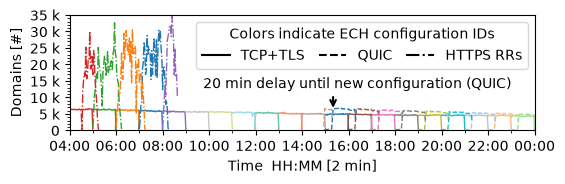

In [4]:
def annotate_quic_delay(ax):
    ax.yaxis.set_major_locator(ticker.MultipleLocator(5_000))
    ax.yaxis.set_minor_locator(ticker.MultipleLocator(1_000))
    ax.set(ylim=(0, 35_000))
    quic_x = mdates.date2num(datetime(2025, 11, 1, 15, 20))
    ax.annotate(
        "            20 min delay until new configuration (QUIC)",
        xy=(quic_x, 6_000),
        xytext=(quic_x, 14_000),
        fontsize=10,
        ha="center",
        va="center",
        arrowprops=dict(arrowstyle="->", color="black", lw=1.5),
    )


plot_day(
    config_id_time,
    date(2025, 11, 1),
    resolution="2m",
    xlim=(datetime(2025, 11, 1, 4), datetime(2025, 11, 2, 0)),
    annotate=annotate_quic_delay,
    file_name="lin_config_id_cloudflare",
    directory=config.FIGURES_DIR / "ech-config-ids",
    show=True,
)
plt.show()

In [16]:
with pl.Config(tbl_rows=500):
    display(config_id_time.filter(
        pl.col(C.role) == "ech-zdns",
        pl.col(C.ech_public_name) == "cloudflare-ech.com",
        pl.col(C.location) == "tud"
    ).sort(C.ts).filter(
        pl.col(C.ts) >= datetime(2025, 11, 1, 4),
        pl.col(C.ts) <= datetime(2025, 11, 2, 0),
        pl.col(C.len) < 15_000
    ))

measurement,ech_public_name,ech_config_id,role,location,timestamp,len
datetime[μs],str,u8,str,str,datetime[μs],u32
2025-11-01 04:30:06,"""cloudflare-ech.com""",185,"""ech-zdns""","""tud""",2025-11-01 04:30:00,"3,550"
2025-11-01 04:30:06,"""cloudflare-ech.com""",185,"""ech-zdns""","""tud""",2025-11-01 04:31:00,"1,545"
2025-11-01 04:30:06,"""cloudflare-ech.com""",185,"""ech-zdns""","""tud""",2025-11-01 04:33:00,4
2025-11-01 04:30:06,"""cloudflare-ech.com""",185,"""ech-zdns""","""tud""",2025-11-01 04:34:00,"4,460"
2025-11-01 04:30:06,"""cloudflare-ech.com""",185,"""ech-zdns""","""tud""",2025-11-01 04:35:00,"7,621"
2025-11-01 04:30:06,"""cloudflare-ech.com""",185,"""ech-zdns""","""tud""",2025-11-01 04:36:00,"4,078"
2025-11-01 04:30:06,"""cloudflare-ech.com""",185,"""ech-zdns""","""tud""",2025-11-01 04:37:00,"11,046"
2025-11-01 04:30:06,"""cloudflare-ech.com""",185,"""ech-zdns""","""tud""",2025-11-01 04:38:00,"8,382"
2025-11-01 04:30:06,"""cloudflare-ech.com""",185,"""ech-zdns""","""tud""",2025-11-01 04:39:00,"8,968"
